# just_drop vs just_drop_hal：四种观测

同一块 ESP32-C3、同一 AP、同一台 TR3000。HAL = `just_drop_hal`（Pass XDP + 应用层 UDP:8080 丢并计 `drop`）；XDP = `just_drop` 固件 + 冷表 `just_drop.elf`（入口 `XDP_DROP`）。计的是进入各自丢弃路径的包，不是无线物理层收包。

| kind | 表 | 负载 | 产出 |
|---|---|---|---|
| **c** Counter | `just_drop_config` / `just_drop_data` | 满速 ~40 s × 3 轮 | **图**：处理 PPS / ADEV / CV |
| **a** Aggregate | `just_drop_run` + `just_drop_agg` | 800 pps × 12 s × 10 轮 | **图**：各段 mean ticks |
| **g** Gauge | `just_drop_run` + `just_drop_gauge` | 800 pps × 12 s × 10 轮 | print 结论（功能语义自检） |
| **t** Trace | `just_drop_run` + `just_drop_trace_summary` | 200 pps × 12 s × 10 轮 | print 结论（ring 是否打满） |

数据：`formal.just_drop_*`（`./xpost-test`，`run` 含 `just_drop`）。本笔记只读库（`.env` 设 `PGSCHEMA=formal`）。

```bash
# Mac, cwd = xpost/
cargo xtask agent --listen 0.0.0.0:9240 --no-monitor
# TR3000
./xpost-test
```


## Counter（kind c）：满速处理 PPS


nan@192.168.110.96:5432/postgres schema=formal
configs=6 samples=246
hal: valid=3/3  PPS=2561  ADEV@1s=9.34% (-5.89–24.58)  CV=15.07%  per-run=[2115, 2778, 2790]
xdp: valid=3/3  PPS=9410  ADEV@1s=4.91% (2.95–6.88)  CV=1.54%  per-run=[9243, 9500, 9487]


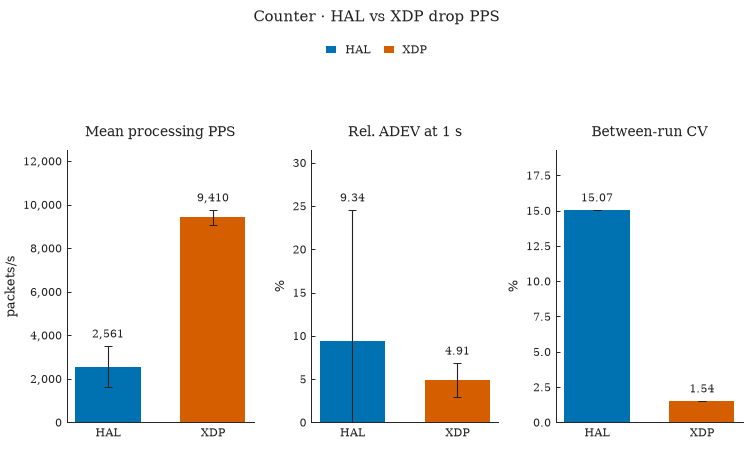

In [1]:
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import (
    cv_bootstrap_ci,
    figure1_summary,
    load_just_drop_config,
    load_just_drop_data,
    mean_across_runs,
    mean_pps,
    mean_t_ci,
    overlapping_relative_adev,
    summarize_variant,
)

plt.ioff()
plt.close("all")
print(dsn_summary())

configs = load_just_drop_config()
assert len(configs), "formal.just_drop_config 空：先跑 ./xpost-test（kinds 含 c）"
samples = load_just_drop_data(configs["config_id"].tolist())
print(f"configs={len(configs)} samples={len(samples)}")

by_variant = defaultdict(list)
adev_runs = defaultdict(list)

for _, row in configs.iterrows():
    cid = int(row["config_id"])
    sub = samples[samples["config_id"] == cid].sort_values("time_ns")
    t_ns = sub["time_ns"].tolist()
    c = sub["counter_value"].tolist()
    variant = row["fw_type"]
    by_variant[variant].append(
        mean_pps(t_ns, c, run_id=str(cid), variant=variant, pair_id=cid)
    )
    adev = overlapping_relative_adev(t_ns, c)
    if adev:
        adev_runs[variant].append({tau: d["adev"] for tau, d in adev.items()})

summaries = {v: summarize_variant(rs) for v, rs in by_variant.items()}
adev_pool = {v: mean_across_runs(rows) for v, rows in adev_runs.items()}


def _at(pool, tau=1.0):
    row = pool.get(tau) or {}
    return row.get("mean"), (row.get("lo"), row.get("hi"))


for v, s in summaries.items():
    a_mean, (a_lo, a_hi) = _at(adev_pool.get(v, {}))
    print(
        f"{v}: valid={s['n_valid']}/{s['n_total']}  "
        f"PPS={s['mean_pps']:.0f}  ADEV@1s={100 * a_mean:.2f}% "
        f"({100 * a_lo:.2f}–{100 * a_hi:.2f})  "
        f"CV={100 * s['cv']:.2f}%  "
        f"per-run={[round(x) for x in s['per_run_pps']]}"
    )

hal, xdp = summaries.get("hal", {}), summaries.get("xdp", {})
hal_pps = hal.get("per_run_pps") or []
xdp_pps = xdp.get("per_run_pps") or []
_, hal_pps_lo, hal_pps_hi = mean_t_ci(hal_pps)
_, xdp_pps_lo, xdp_pps_hi = mean_t_ci(xdp_pps)
hal_cv, _, _ = cv_bootstrap_ci(hal_pps)
xdp_cv, _, _ = cv_bootstrap_ci(xdp_pps)
hal_a, hal_a_ci = _at(adev_pool.get("hal", {}))
xdp_a, xdp_a_ci = _at(adev_pool.get("xdp", {}))

fig, _ = figure1_summary(
    hal_mean_pps=hal.get("mean_pps", float("nan")),
    xdp_mean_pps=xdp.get("mean_pps", float("nan")),
    hal_pps_ci=(hal_pps_lo, hal_pps_hi),
    xdp_pps_ci=(xdp_pps_lo, xdp_pps_hi),
    hal_adev_1s=hal_a,
    xdp_adev_1s=xdp_a,
    hal_adev_ci=hal_a_ci,
    xdp_adev_ci=xdp_a_ci,
    hal_cv=hal_cv,
    xdp_cv=xdp_cv,
    title="Counter · HAL vs XDP drop PPS",
)
display(fig)
plt.close(fig)


## Aggregate（kind a）：固定 800 pps · mean ticks


fw_type          hal   xdp
name                      
rx_processing  120.2  31.8
xdp_execution   75.5  17.1
post_action     41.3  13.2
xdp_dispatch     3.3   1.6
rx_processing: HAL=120.2±12.9  XDP=31.8±0.3  ratio=3.78×


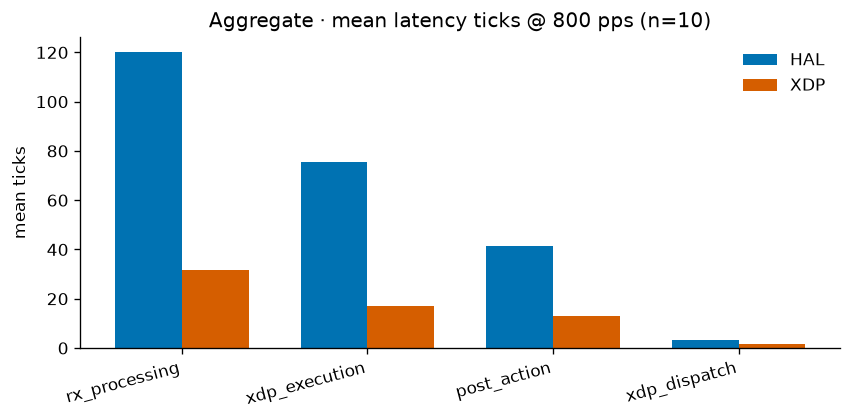

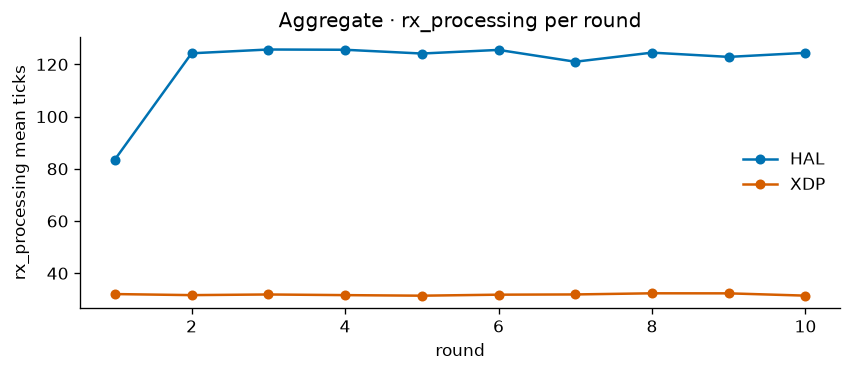

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from utils.experiment import load_just_drop_agg, load_just_drop_run

runs_a = load_just_drop_run(kind="a")
assert len(runs_a), "formal.just_drop_run 无 kind=a"
agg = load_just_drop_agg(runs_a["run_id"].tolist())
merged = agg.merge(runs_a[["run_id", "fw_type"]], on="run_id")

order = ["rx_processing", "xdp_execution", "post_action", "xdp_dispatch"]
means = (
    merged.groupby(["name", "fw_type"], as_index=False)["mean_ticks"]
    .mean()
    .pivot(index="name", columns="fw_type", values="mean_ticks")
    .reindex(order)
)
print(means.round(1).to_string())

hal_rx = merged[(merged["fw_type"] == "hal") & (merged["name"] == "rx_processing")]["mean_ticks"]
xdp_rx = merged[(merged["fw_type"] == "xdp") & (merged["name"] == "rx_processing")]["mean_ticks"]
print(
    f"rx_processing: HAL={hal_rx.mean():.1f}±{hal_rx.std(ddof=1):.1f}  "
    f"XDP={xdp_rx.mean():.1f}±{xdp_rx.std(ddof=1):.1f}  "
    f"ratio={hal_rx.mean() / xdp_rx.mean():.2f}×"
)

x = np.arange(len(order))
w = 0.36
fig, ax = plt.subplots(figsize=(7.2, 3.6), dpi=120)
ax.bar(x - w / 2, means["hal"].values, w, label="HAL", color="#0072B2")
ax.bar(x + w / 2, means["xdp"].values, w, label="XDP", color="#D55E00")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=15, ha="right")
ax.set_ylabel("mean ticks")
ax.set_title("Aggregate · mean latency ticks @ 800 pps (n=10)")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
display(fig)
plt.close(fig)

# per-round rx_processing
fig2, ax2 = plt.subplots(figsize=(7.2, 3.2), dpi=120)
for fw, color in (("hal", "#0072B2"), ("xdp", "#D55E00")):
    ys = (
        merged[(merged["fw_type"] == fw) & (merged["name"] == "rx_processing")]
        .sort_values("run_id")["mean_ticks"]
        .tolist()
    )
    ax2.plot(range(1, len(ys) + 1), ys, "o-", color=color, label=fw.upper(), ms=5)
ax2.set_xlabel("round")
ax2.set_ylabel("rx_processing mean ticks")
ax2.set_title("Aggregate · rx_processing per round")
ax2.legend(frameon=False)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
fig2.tight_layout()
display(fig2)
plt.close(fig2)


## Gauge（kind g）+ Trace（kind t）：功能自检（不画图）


In [ ]:
from utils.experiment import (
    load_just_drop_gauge,
    load_just_drop_run,
    load_just_drop_trace_summary,
)

runs_g = load_just_drop_run(kind="g")
runs_t = load_just_drop_run(kind="t")
assert len(runs_g) and len(runs_t), "缺 kind=g 或 kind=t"

gauge = load_just_drop_gauge(runs_g["run_id"].tolist()).merge(
    runs_g[["run_id", "fw_type"]], on="run_id"
)
rxq = gauge[gauge["name"] == "rx_queue_depth"]
for fw, g in rxq.groupby("fw_type"):
    print(
        f"gauge rx_queue_depth [{fw}]: "
        f"n={len(g)}  peak mean/min/max="
        f"{g['peak'].mean():.1f}/{g['peak'].min()}/{g['peak'].max()}  "
        f"current mean={g['current'].mean():.1f}"
    )
other = gauge[gauge["name"] != "rx_queue_depth"]
if len(other):
    z = (other["peak"] == 0).all() and (other["current"] == 0).all()
    print(
        f"gauge other names ({', '.join(sorted(other['name'].unique()))}): "
        f"{'all zero (expected: no TX / no trace in kind-g)' if z else 'NONZERO — check'}"
    )

trace = load_just_drop_trace_summary(runs_t["run_id"].tolist()).merge(
    runs_t[["run_id", "fw_type"]], on="run_id"
)
for fw, t in trace.groupby("fw_type"):
    print(
        f"trace [{fw}]: n={len(t)}  len mean/min/max="
        f"{t['len'].mean():.0f}/{t['len'].min()}/{t['len'].max()}  "
        f"dropped mean/min/max="
        f"{t['dropped'].mean():.0f}/{t['dropped'].min()}/{t['dropped'].max()}"
    )

hal_peak = int(rxq.loc[rxq["fw_type"] == "hal", "peak"].max())
xdp_peak = int(rxq.loc[rxq["fw_type"] == "xdp", "peak"].max())
print(
    f"\n结论 gauge: HAL peak={hal_peak}（队列打满）；"
    f"XDP peak={xdp_peak}（XDP_DROP 不入 app 队列，语义正确）。"
)
print(
    f"结论 trace: 两侧 len 恒满 cap、dropped ≫ 0；"
    f"摘要可用，kind_hist 仍为空 stub。"
)


## 读数要点

**Counter / Aggregate** 是性能对比主图。满速 PPS 与固定 pps 下的 mean ticks 都显示 XDP 明显轻于 HAL。

**Gauge / Trace** 只做功能自检：HAL 队列打满、XDP 不入队、trace ring 打满——不单独画图。
